# PID Tuning Rules: Comparison on FOPDT Plants

`04_pid_tuning` | level 2 | experiment id(s): `exp_04_pid_tuning_comparison`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 8 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Compute PID settings from a FOPDT model with seven rules (Ziegler-Nichols open and closed
  loop, Cohen-Coon, Tyreus-Luyben, IMC, SIMC, relay autotune followed by Ziegler-Nichols).
- Compare them with the same protocol on four plants with `L/T` = 0.1, 0.2, 0.5, 1.0 using IAE,
  overshoot, settling time, control variation, gain margin, phase margin and peak sensitivity `Ms`.
- Estimate `Ku` and `Pu` with a relay experiment and state how large its error is.

## 2. Real-World Engineering Problem

A technician tunes a new loop on site. The choice of rule decides whether the loop is sluggish,
oscillatory or close to instability, and the plant's `L/T` ratio (dead time relative to time
constant) largely decides which rule behaves. A rule that is acceptable at `L/T = 0.1`
can have almost no margin at `L/T = 1`.

## 3. Research Background

Ziegler and Nichols (1942) gave the first widely used open- and closed-loop rules, aiming at
quarter-amplitude decay. Cohen and Coon (1953) added a correction for larger dead time.
Model-based design followed: IMC-PID (Rivera et al., 1986), then SIMC (Skogestad, 2003).
Astrom and Hagglund (1984) introduced the relay experiment, which finds the ultimate point without
driving the loop to instability. Tyreus and Luyben (1992) proposed less oscillatory ultimate-point
rules.

## 4. Research Literature

The rules were transcribed from their commonly published forms. The primary papers are listed
below, but their **full texts were not read** during this build, so the formula transcription is
verified by hand computation in unit tests only, not against the original equations. The
Cohen-Coon and Tyreus-Luyben bibliographic records are only partially verified (see the table).

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| zn1942 | Ziegler, J. G.; Nichols, N. B. (1942). Optimum settings for automatic controllers. Transactions of the ASME, 64, 759-768. | Origin of the open-loop (reaction curve) and closed-loop (ultimate gain) PID rules. | Tuned for a pneumatic controller and quarter-amplitude decay; the loops are often oscillatory by modern criteria. | verified (2026-11-25, web search of publisher/index/library record). Facsimile of the paper and several citation lists agree on volume and pages. |
| cc1953 | Cohen, G. H.; Coon, G. A. (1953). Theoretical consideration of retarded control. Transactions of the ASME, 75, 827-834. | Reaction-curve tuning rules that account for large dead time. | Rules are for quarter-amplitude decay; the title is cited with small wording variants in the literature. | partial (2026-11-25, web search of publisher/index/library record). Authors, year, volume and pages agree across several third-party reference lists; the primary page was not seen. Title wording varies. |
| tl1992 | Tyreus, B. D.; Luyben, W. L. (1992). Tuning PI controllers for integrator/dead time processes. Industrial & Engineering Chemistry Research. doi:10.1021/ie00011a029. | Source of the Tyreus-Luyben ultimate-point rules (less oscillatory than Z-N). | Developed for PI on integrator plus dead time processes; use for PID is an extension in common practice. | partial (2026-11-25, web search of publisher/index/library record). Title, authors, year and DOI seen on an index record. Volume and pages were not confirmed and are left blank. |
| rmm1986 | Rivera, D. E.; Morari, M.; Skogestad, S. (1986). Internal model control: PID controller design. Industrial & Engineering Chemistry Process Design and Development, 25(1), 252-265. doi:10.1021/i200032a041. | Derives PID settings from the IMC procedure with one tuning parameter. | Model based; assumes a reasonably accurate low-order model. | verified (2026-11-25, web search of publisher/index/library record). Author-hosted record gives journal, volume, issue and pages. |
| skogestad2003 | Skogestad, S. (2003). Simple analytic rules for model reduction and PID controller tuning. Journal of Process Control, 13(4), 291-309. doi:10.1016/S0959-1524(02)00062-8. | SIMC rules and the half rule for effective delay. | An erratum exists (J. Process Control 14, 2004, p. 465). | verified (2026-11-25, web search of publisher/index/library record). Author-hosted record and an index record agree; the erratum was seen. |
| ah1984 | Astrom, K. J.; Hagglund, T. (1984). Automatic tuning of simple regulators with specifications on phase and amplitude margins. Automatica, 20(5), 645-651. doi:10.1016/0005-1098(84)90014-1. | Relay feedback experiment for estimating the ultimate gain and period. | The describing-function estimate is approximate for non-sinusoidal limit cycles. | verified (2026-11-25, web search of publisher/index/library record). University repository record with abstract, volume, issue, pages. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Plant $G(s)=Ke^{-Ls}/(Ts+1)$, controller $C(s)=K_p\left(1+\frac{1}{T_is}+T_ds\right)$.

| Rule | $K_p$ | $T_i$ | $T_d$ |
|---|---|---|---|
| Z-N open loop | $1.2\,T/(KL)$ | $2L$ | $0.5L$ |
| Z-N closed loop | $0.6K_u$ | $0.5P_u$ | $0.125P_u$ |
| Cohen-Coon | $\frac{T}{KL}(\frac43+\frac{L}{4T})$ | $L\frac{32+6L/T}{13+8L/T}$ | $\frac{4L}{11+2L/T}$ |
| Tyreus-Luyben | $K_u/2.2$ | $2.2P_u$ | $P_u/6.3$ |
| IMC (Pade 1/1), filter $\lambda$ | $\frac{T+L/2}{K(\lambda+L/2)}$ | $T+L/2$ | $\frac{TL}{2T+L}$ |
| SIMC PI, $\tau_c=L$ | $\frac{T}{K(\tau_c+L)}$ | $\min(T,4(\tau_c+L))$ | 0 |

$K_u$ and $P_u$ follow from the phase crossover $\omega_u$: $\omega_uL+\arctan(\omega_uT)=\pi$,
$K_u=\sqrt{1+(\omega_uT)^2}/K$, $P_u=2\pi/\omega_u$.

**Relay experiment.** A relay of amplitude $d$ produces a limit cycle of output amplitude $a$ and
period $P_u$. The describing-function estimate is $K_u\approx 4d/(\pi a)$. It assumes a sinusoidal
output; the error is nonzero when the limit cycle is not sinusoidal.

**Margins.** With loop $L(j\omega)=C(j\omega)G(j\omega)$: gain margin $=1/|L(j\omega_{pc})|$ at the
phase crossover, phase margin $=\pi+\angle L(j\omega_{gc})$ at the gain crossover, and
$M_s=\max_\omega|1/(1+L(j\omega))|$.

## 6. System Modeling

Four plants with `K = 1`, `T = 5 s` and `L` = 0.5, 1, 2.5, 5 s (`L/T` = 0.1, 0.2, 0.5, 1.0),
`Ts = 0.05 s`. Controller `PID.from_times` with derivative filter `Tf = Td/10` and output
limits off, so the comparison reflects the rule and not saturation. Illustrative plants, not
measured.

## 7. Dataset and Measurement Data

No dataset; simulated plants. Relay experiments use `d = 0.5` and no noise.

## 8. Algorithm Architecture

Protocol (same for every rule and plant): setpoint step at 0, load (input) step 0.3 at
`10 (T+L)`, run `20 (T+L)`. Setpoint metrics are taken on the first half. Frequency-domain
margins use the continuous ideal PID and the exact delay, so they ignore the derivative filter and
the sampling delay (about `Ts/2`).

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import PID
from control_lab.controllers import tuning as tn
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import iae, step_response_metrics, total_variation
from control_lab.models import FOPDTPlant
from control_lab.simulation import run_closed_loop

EXP = "exp_04_pid_tuning_comparison"
K, T, Ts = 1.0, 5.0, 0.05
LS = [0.5, 1.0, 2.5, 5.0]

def margins(kp, ti, td, K, T, L, w=None):
    w = np.logspace(-3, 2, 60000) if w is None else w
    s = 1j * w
    C = kp * (1 + 1 / (ti * s) + td * s) if np.isfinite(ti) else kp * (1 + td * s)
    Lj = C * K * np.exp(-s * L) / (T * s + 1)
    mag, ph = np.abs(Lj), np.unwrap(np.angle(Lj))
    out = {"Ms": float(np.max(1 / np.abs(1 + Lj)))}
    i = np.flatnonzero(ph <= -np.pi)
    out["gain_margin"] = float(1 / mag[i[0]]) if i.size else float("inf")
    j = np.flatnonzero((mag[:-1] >= 1) & (mag[1:] < 1))
    out["phase_margin_deg"] = float(np.degrees(np.pi + ph[j[0]])) if j.size else float("nan")
    return out

def rules(L):
    Ku, Pu = tn.ultimate_point_fopdt(K, T, L)
    try:
        Kr, Pr, info = tn.relay_experiment(FOPDTPlant(K, T, L, Ts), d=0.5, Ts=Ts, t_end=max(120.0, 25 * Pu))
    except RuntimeError:
        Kr = Pr = None
    out = {
        "ZN-open": tn.ziegler_nichols_open(K, T, L),
        "ZN-closed": tn.ziegler_nichols_closed(Ku, Pu),
        "Cohen-Coon": tn.cohen_coon(K, T, L),
        "Tyreus-Luyben": tn.tyreus_luyben(Ku, Pu),
        "IMC (lam=max(L,0.2T))": tn.imc_pid(K, T, L, lam=max(L, 0.2 * T)),
        "SIMC PI": tn.simc_pi(K, T, L),
    }
    if Kr is not None:
        out["relay + ZN"] = tn.ziegler_nichols_closed(Kr, Pr)
    return out, (Ku, Pu), (Kr, Pr)

def run_rule(g, L):
    td = g["td"]
    ctl = PID.from_times(g["kp"], g["ti"], td, Ts=Ts, tf=(td / 10 if td > 0 else 0.0))
    n = int(20 * (T + L) / Ts); t = np.arange(n) * Ts
    dist = np.where(t >= 10 * (T + L), 0.3, 0.0)
    o = run_closed_loop(FOPDTPlant(K, T, L, Ts), ctl, np.ones(n), Ts, disturbance=dist)
    return t, o, int(10 * (T + L) / Ts)

`rules(L)` returns the settings from each rule, `run_rule` applies the common protocol, and
`margins` evaluates robustness in the frequency domain.

## 10. Simulation and Numerical Analysis

Plants and the protocol are in sections 6 and 8. All simulations are deterministic (no noise).

## 11. Experimental Validation

Level: **software simulation**. Independent references: (a) the phase-crossover `Ku`, `Pu`
against a frequency-grid evaluation of `|G(jw)|`, (b) a simulation with the P gain just below and
above `Ku`. No controller-in-the-loop or hardware test was run.

## 12. Performance Evaluation

In [3]:
checks, rows, store = [], [], {}
ku_table = {}
for L in LS:
    R, (Ku, Pu), (Kr, Pr) = rules(L)
    # (a) Ku/Pu against the frequency grid
    w = np.logspace(-3, 2, 200000)
    ph = -w * L - np.arctan(w * T)
    idx = np.flatnonzero(ph <= -np.pi)[0]
    Ku_grid = np.sqrt(1 + (w[idx] * T) ** 2) / K
    checks.append(check(f"Ku grid vs root-finder, L={L}", abs(Ku_grid - Ku) / Ku < 1e-3, f"{Ku_grid:.4f} vs {Ku:.4f}"))
    # (b) P-only loop just below / above Ku
    def p_loop(gain):
        n = int(40 * Pu / Ts)
        o = run_closed_loop(FOPDTPlant(K, T, L, Ts), PID(kp=gain, Ts=Ts), np.ones(n), Ts)
        y = o["y"]; q = len(y) // 4
        return np.abs(y[-q:] - y[-1]).max() / max(np.abs(y[q:2 * q] - y[-1]).max(), 1e-12)
    low, high = p_loop(0.8 * Ku), p_loop(1.2 * Ku)
    checks.append(check(f"P loop decays at 0.8 Ku and grows at 1.2 Ku, L={L}", low < 1.0 < high,
                        f"late/mid amplitude ratio {low:.2f} (0.8 Ku), {high:.2f} (1.2 Ku)"))
    ku_table[str(L)] = {"Ku_exact": Ku, "Pu_exact": Pu, "Ku_relay": Kr, "Pu_relay": Pr,
                        "Ku_relay_error_percent": None if Kr is None else 100 * (Kr - Ku) / Ku,
                        "Pu_relay_error_percent": None if Pr is None else 100 * (Pr - Pu) / Pu}
    for name, g in R.items():
        t, o, i_d = run_rule(g, L)
        diverged = bool(np.max(np.abs(o["y"])) > 20)
        m = step_response_metrics(t[:i_d], o["y"][:i_d], 1.0)
        mg = margins(g["kp"], g["ti"], g["td"], K, T, L)
        mg_L = margins(g["kp"], g["ti"], g["td"], K, T, 1.5 * L)
        row = {"L_over_T": L / T, "rule": name, "kp": g["kp"], "ti": g["ti"], "td": g["td"],
               "diverged": diverged,
               "iae_setpoint": None if diverged else iae(t[:i_d], o["e"][:i_d]),
               "iae_load": None if diverged else iae(t[i_d:], o["e"][i_d:]),
               "overshoot_percent": None if diverged else m["overshoot_percent"],
               "settling_time_s": None if diverged else m["settling_time"],
               "total_variation_u": None if diverged else total_variation(o["u"][:i_d]),
               "gain_margin": mg["gain_margin"], "phase_margin_deg": mg["phase_margin_deg"], "Ms": mg["Ms"],
               "stable_if_delay_x1.5": bool(mg_L["gain_margin"] > 1 and mg_L["phase_margin_deg"] > 0)}
        rows.append(row); store[(L, name)] = (t, o)
import pandas as pd
df = pd.DataFrame(rows)
metrics = {"ultimate_point": ku_table, "table": rows}
print(df[["L_over_T", "rule", "kp", "ti", "td", "iae_setpoint", "iae_load", "overshoot_percent", "gain_margin", "phase_margin_deg", "Ms", "stable_if_delay_x1.5"]].round(2).to_string(index=False))

 L_over_T                  rule    kp    ti   td  iae_setpoint  iae_load  overshoot_percent  gain_margin  phase_margin_deg   Ms  stable_if_delay_x1.5
      0.1               ZN-open 12.00  1.00 0.25          1.86      0.04              93.39         1.42             36.11 3.42                  True
      0.1             ZN-closed  9.81  0.96 0.24          1.52      0.04              75.89         1.77             36.34 2.32                  True
      0.1            Cohen-Coon 13.58  1.18 0.18          2.66      0.05             109.92         1.37             25.69 3.98                 False
      0.1         Tyreus-Luyben  7.43  4.24 0.31          1.21      0.17               7.92         1.90             70.79 2.11                  True
      0.1 IMC (lam=max(L,0.2T))  4.20  5.25 0.24          1.47      0.37               1.61         3.88             78.15 1.36                  True
      0.1               SIMC PI  5.00  4.00 0.00          1.26      0.24              10.00         

The table is the benchmark. The relay estimates and their errors against the exact ultimate point
are printed below.

In [4]:
print(pd.DataFrame(ku_table).T.round(3))
checks.append(check("relay produced a sustained limit cycle for every plant", all(v["Ku_relay"] is not None for v in ku_table.values()), str({k: v["Ku_relay"] is not None for k, v in ku_table.items()})))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

     Ku_exact  Pu_exact  Ku_relay  Pu_relay  Ku_relay_error_percent  \
0.5    16.351     1.925    12.775       2.0                 -21.869   
1.0     8.502     3.721     6.782       3.8                 -20.238   
2.5     3.807     8.553     3.208       8.4                 -15.739   
5.0     2.262    15.485     2.005      15.0                 -11.371   

     Pu_relay_error_percent  
0.5                   3.896  
1.0                   2.130  
2.5                  -1.786  
5.0                  -3.134  
9 of 9 checks passed


## 13. Visualization and Interpretation

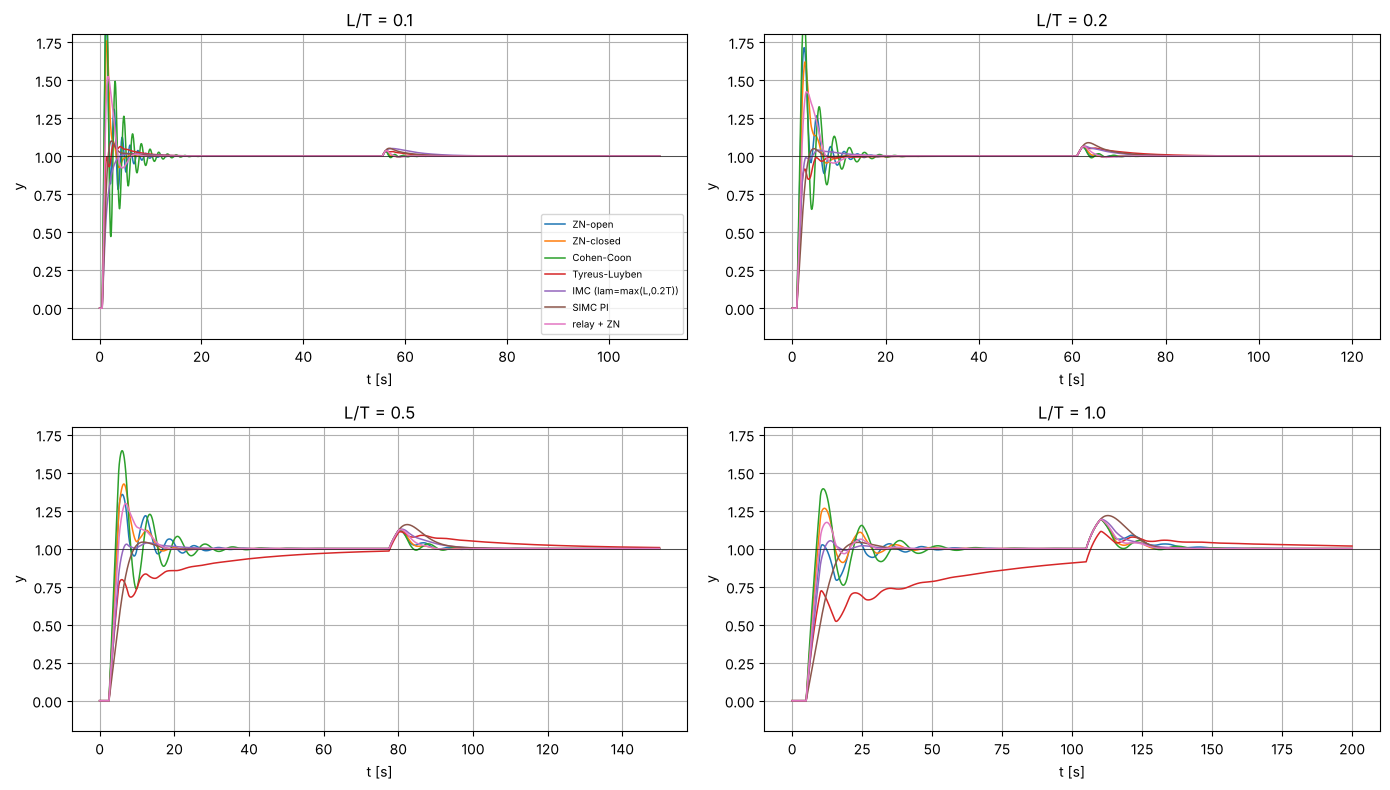

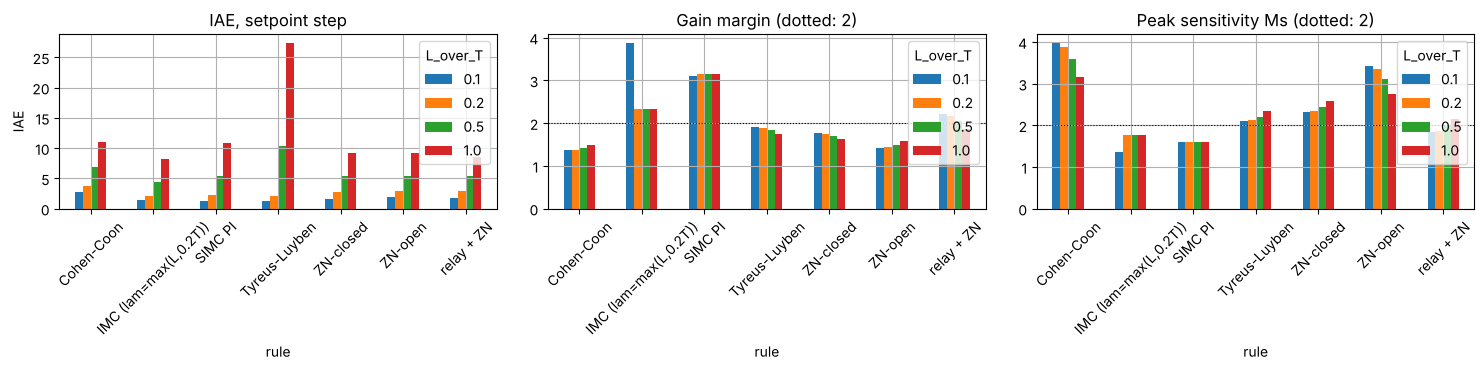

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, L in zip(ax.ravel(), LS):
    for name in [r for (l_, r) in store if l_ == L]:
        t, o = store[(L, name)]
        if np.max(np.abs(o["y"])) < 5:
            a.plot(t, o["y"], lw=1.1, label=name)
    a.set(title=f"L/T = {L / T:.1f}", xlabel="t [s]", ylabel="y", ylim=(-0.2, 1.8))
    a.axhline(1, color="k", lw=0.4)
ax[0, 0].legend(fontsize=7)
fig.tight_layout()
figs = [save_figure(fig, EXP, "step_and_load_responses")]
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
pv = df[~df["diverged"]].pivot(index="rule", columns="L_over_T", values="iae_setpoint")
pv.plot.bar(ax=ax[0], rot=45); ax[0].set(title="IAE, setpoint step", ylabel="IAE")
df.pivot(index="rule", columns="L_over_T", values="gain_margin").plot.bar(ax=ax[1], rot=45); ax[1].axhline(2, color="k", ls=":", lw=0.8); ax[1].set(title="Gain margin (dotted: 2)")
df.pivot(index="rule", columns="L_over_T", values="Ms").plot.bar(ax=ax[2], rot=45); ax[2].axhline(2, color="k", ls=":", lw=0.8); ax[2].set(title="Peak sensitivity Ms (dotted: 2)")
fig.tight_layout()
figs.append(save_figure(fig, EXP, "metrics_by_rule"))
plt.show()

Read the figures with the table, not alone. Gain margin and `Ms` are the robustness measures;
the dotted lines at 2 are common design targets in the PID literature, used here only as a
reference level, not as a pass/fail criterion.

## 14. Research Discussion and Limitations

**Observed in this run (facts, FOPDT plants, protocol of section 8; numbers from the table above).**
- **Relay autotune.** The describing-function `Ku` is 11% to 22% below the exact value
  (largest at `L/T = 0.1`, smallest at `L/T = 1`); `Pu` is within 4%. Inference (sampling effect not
  varied in this notebook): the error comes from the describing-function approximation.
- **Robustness of the classical rules.** Ziegler-Nichols (open and closed) and Cohen-Coon give gain
  margins of 1.37 to 1.77, below the common target of 2, and `Ms` of 2.3 to 4.0. Cohen-Coon loses
  stability when the delay grows by 50% at `L/T` = 0.1, 0.2 and 0.5.
- **Overshoot.** Ziegler-Nichols and Cohen-Coon overshoot the setpoint step by 6% to 110%
  (setpoint weight `b = 1`, so the proportional kick is included); Tyreus-Luyben, IMC and SIMC stay
  at about 10% or less.
- **Speed versus robustness.** IMC has the lowest setpoint IAE for `L/T` of 0.2, 0.5 and 1.0;
  Tyreus-Luyben has the lowest at `L/T = 0.1` but the slowest setpoint response at
  `L/T = 1` (IAE 27.4 against 8.2 for IMC). The load-disturbance IAE tends to favour the aggressive
  rules (at `L/T = 0.1`: 0.04 for Ziegler-Nichols open loop, 0.37 for IMC).

**Inference (not tested here).** Because the rankings change with `L/T` and with the metric, no
single rule is best; the choice depends on whether setpoint tracking, load rejection or margin
dominates.

**Limits.** (1) The rules assume a FOPDT approximation, and real plants add higher-order dynamics
(notebook 02). (2) Rule transcription was checked by hand computation in unit tests, not against
the original papers. (3) Margins ignore the derivative filter and sampling. (4) `L/T` near 1 is
outside the intended range of some rules, so poor results there are expected. (5) The disturbance
enters at the plant input; another location changes the load-rejection ranking. (6) One `K` and
one `T`; the dependence on `T` was not varied.

## 15. Summary, Exercises, and Further Research

**Key insights.** Choose the rule by the plant's `L/T`, and check the margins of the result
before commissioning.

**Exercises.** (1) Add a lag-dominant plant (`L/T = 0.02`) and compare SIMC with IMC at several
`lambda`. (2) Add measurement noise and rank the rules by control variation. (3) Replace the
relay amplitude and hysteresis and report the sensitivity of the `Ku` error.

**Related.** PID (notebook 03), identification (02), fuzzy PI (08), MPC (12).
**Research directions.** Robust tuning with explicit `Ms` constraints, and autotuning under
noise and load disturbances.

In [6]:
rec = ExperimentRecord(
    experiment_id=EXP, title="PID tuning rule comparison on FOPDT plants",
    notebook="notebooks/02_classical/04_pid_tuning.ipynb",
    algorithm="ZN open/closed, Cohen-Coon, Tyreus-Luyben, IMC, SIMC, relay autotune",
    application="Generic process loop (illustrative)", plant_model="FOPDT K=1, T=5 s, L in {0.5,1,2.5,5} s",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated plants, no noise."},
    metrics=metrics, checks=checks, sampling_time_s=Ts, random_seed=None, number_of_trials=len(rows),
    controller_parameters={"rules": sorted({r["rule"] for r in rows}), "derivative_filter": "Tf = Td/10"},
    plant_parameters={"K": K, "T_s": T, "L_s": LS}, input_configuration={"setpoint_step": 1.0},
    disturbance_configuration={"input_step": 0.3, "at": "10 (T+L)"},
    operating_conditions={"saturation": "none", "noise": "none"}, figure_references=figs,
    limitations=["FOPDT plants only, one K and T; four L/T values.",
                 "Rule formulas transcribed from commonly published forms; not checked against the original papers.",
                 "Frequency-domain margins ignore the derivative filter and sampling delay.",
                 "No noise, saturation, or hardware validation."])
print(rec.save())

experiments/results/exp_04_pid_tuning_comparison.json
